# 04 · Serie de tiempo: ¿cuántos pedidos recibirá la tienda cada día?

**La pregunta:** ¿cuántos pedidos va a recibir la tienda en los próximos días? Saberlo ayuda a planificar cuántas personas y cuántos repartidores se necesitan.

Aquí no predecimos algo de un pedido, sino **cómo sigue una cantidad a lo largo del tiempo**: es un problema de **serie de tiempo**. Usamos la serie que preparamos en el cuaderno 01, con los pedidos de cada día entre el 5 de enero de 2017 y el 19 de agosto de 2018 (592 días).

**¿Qué tiene de especial una serie de tiempo?**

- El orden importa: hay que predecir el futuro usando solo el pasado, así que **nunca mezclamos los días al azar**.
- En el cuaderno 01 vimos que la serie tiene **tendencia** (la tienda crece), un **patrón semanal** (los lunes se vende más que los sábados) y un día muy raro: el Black Friday.

**Métricas:** las mismas de la regresión, ahora medidas en pedidos por día: MAE (cuántos pedidos se equivoca en promedio el pronóstico), RMSE, MAPE (el error en porcentaje) y R².

**Pasos que seguimos**

1. Limpiamos el Black Friday para que no confunda a los modelos.
2. Separamos los días por fecha en entrenamiento, validación y prueba.
3. Definimos cómo evaluar: simulamos que estamos parados en distintos lunes y pronosticamos las 4 semanas siguientes.
4. Comparamos dos predicciones simples (*baselines*) con dos modelos clásicos de series de tiempo: **Holt-Winters** y **SARIMA**.
5. Elegimos el mejor con validación, lo medimos en prueba y lo guardamos para la aplicación.

**Cómo ejecutarlo:** igual que los cuadernos anteriores. Primero hay que ejecutar el cuaderno 01.

In [1]:
# Importamos las librerías. De statsmodels usamos los dos modelos de series de tiempo
import json
import sys
import warnings
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
from cycler import cycler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Si estamos en Colab, leemos los datos desde Google Drive; si no, desde la carpeta del proyecto
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/proyecto")  # cambiar si la carpeta está en otra ubicación de Drive
else:
    BASE = Path("..")

ARCHIVO = BASE / "data" / "processed" / "pedidos_diarios.csv"
MODELOS = BASE / "models"
if not ARCHIVO.exists():
    raise FileNotFoundError(f"No se encontró {ARCHIVO.resolve()}. Ejecuta primero el cuaderno 01.")
MODELOS.mkdir(exist_ok=True)
print(f"statsmodels {statsmodels.__version__} · datos: {ARCHIVO.resolve()}")

pd.set_option("display.float_format", "{:.2f}".format)

# Los mismos colores que en los cuadernos anteriores
SUPERFICIE, TINTA, TINTA_2, TENUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": TINTA, "axes.titlecolor": TINTA, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": TINTA_2, "axes.edgecolor": EJE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA]),
})

statsmodels 0.15.0 · datos: D:\Buri\proyecto\data\processed\pedidos_diarios.csv


In [2]:
# Cargamos la serie diaria (una fila por día)
original = pd.read_csv(ARCHIVO, parse_dates=["fecha"], index_col="fecha")["pedidos"].asfreq("D")
print(f"{len(original)} días, del {original.index.min():%d-%m-%Y} al {original.index.max():%d-%m-%Y}")

592 días, del 05-01-2017 al 19-08-2018


## 1. Limpiamos el Black Friday

El 24 de noviembre de 2017 hubo 1.176 pedidos, y los días siguientes también fueron muy altos (ofertas como el *Cyber Monday*). Si dejamos esos días tal cual, los modelos pueden creer que la tienda creció de golpe. Por eso **reemplazamos del 24 al 29 de noviembre de 2017 por el promedio del mismo día de la semana en las dos semanas anteriores**. Por ejemplo, el viernes 24 pasa a valer el promedio de los viernes 17 y 10 de noviembre.

,original,limpio
fecha,,
2017-11-24,1176,181.00
2017-11-25,499,154.00
2017-11-26,391,166.00
2017-11-27,403,217.50
2017-11-28,380,210.00
2017-11-29,323,193.50


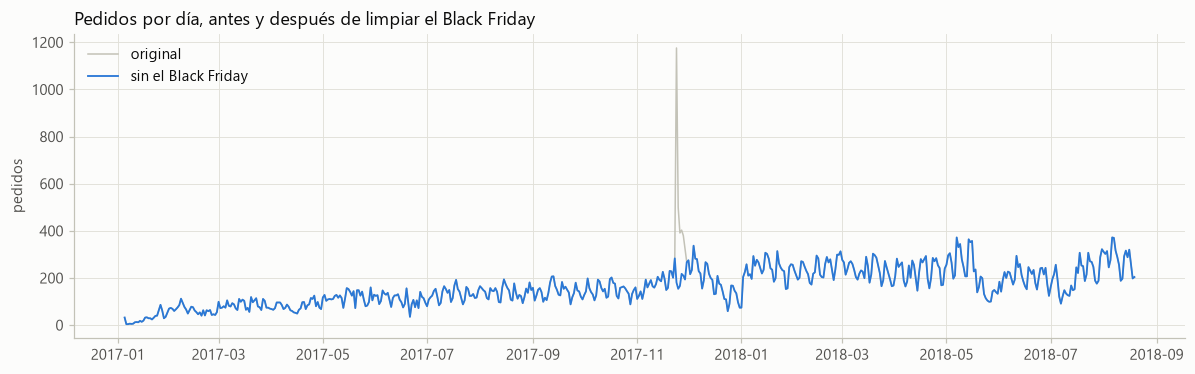

In [3]:
# Reemplazamos los 6 días del Black Friday por el promedio del mismo día de la semana de las 2 semanas anteriores
serie = original.astype(float).copy()
dias_black_friday = pd.date_range("2017-11-24", "2017-11-29", freq="D")
for dia in dias_black_friday:
    serie[dia] = (original[dia - pd.Timedelta(days=7)] + original[dia - pd.Timedelta(days=14)]) / 2
display(pd.DataFrame({"original": original[dias_black_friday], "limpio": serie[dias_black_friday]}))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(original.index, original, color=EJE, linewidth=1, label="original")
ax.plot(serie.index, serie, color=AZUL, linewidth=1.2, label="sin el Black Friday")
ax.set(title="Pedidos por día, antes y después de limpiar el Black Friday", ylabel="pedidos")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. Separamos los días por fecha

| Conjunto | Días | ¿Para qué lo usamos? |
|---|---|---|
| Entrenamiento | del 5 de enero de 2017 al 29 de abril de 2018 (480 días) | para que los modelos aprendan |
| Validación | del 30 de abril al 24 de junio de 2018 (8 semanas) | para elegir el modelo y su configuración |
| Prueba | del 25 de junio al 19 de agosto de 2018 (8 semanas) | para medir el modelo final una sola vez |

In [4]:
# Fechas de corte de cada conjunto
INICIO_VAL, INICIO_PRU = pd.Timestamp("2018-04-30"), pd.Timestamp("2018-06-25")
FIN = serie.index.max()
entrenamiento = serie[:INICIO_VAL - pd.Timedelta(days=1)]
print(f"Entrenamiento: {len(entrenamiento)} días · validación: {len(serie[INICIO_VAL:INICIO_PRU - pd.Timedelta(days=1)])} días · "
      f"prueba: {len(serie[INICIO_PRU:])} días")

Entrenamiento: 480 días · validación: 56 días · prueba: 56 días


## 3. ¿Cómo evaluamos un pronóstico?

En la aplicación, el usuario va a pedir un pronóstico de hasta **4 semanas (28 días)**. Para evaluar algo parecido, hacemos una **evaluación con origen móvil**:

1. Nos paramos en un lunes y le damos al modelo **solo los días anteriores**.
2. El modelo pronostica las 4 semanas siguientes y comparamos con lo que pasó de verdad.
3. Avanzamos una semana y repetimos, hasta el final del período.

Así, en validación y en prueba simulamos **8 lunes** distintos cada uno. Es como si usáramos el modelo de verdad, semana a semana, sin mirar nunca el futuro.

In [5]:
# Función de evaluación con origen móvil: cada lunes, pronosticar hasta 28 días con los datos anteriores
def evaluar_pronostico(pronosticar, inicio, fin, horizonte=28, paso=7):
    resultados = []
    origen = inicio
    while origen <= fin:
        historia = serie[:origen - pd.Timedelta(days=1)]
        futuro = serie[origen:min(origen + pd.Timedelta(days=horizonte - 1), fin)]
        resultados.append(pd.DataFrame({"origen": origen, "fecha": futuro.index, "real": futuro.to_numpy(),
                                        "pronostico": pronosticar(historia, len(futuro))}))
        origen += pd.Timedelta(days=paso)
    return pd.concat(resultados, ignore_index=True)


def metricas(real, pronostico):
    return {"MAE": mean_absolute_error(real, pronostico),
            "RMSE": root_mean_squared_error(real, pronostico),
            "MAPE (%)": 100 * mean_absolute_percentage_error(real, pronostico),
            "R²": r2_score(real, pronostico)}

## 4. Predicciones simples para comparar (*baselines*)

- **La semana pasada:** el pronóstico de cada día es lo que pasó el mismo día de la semana anterior. Si el lunes pasado hubo 250 pedidos, el próximo lunes también.
- **Promedio de las últimas 4 semanas:** el pronóstico de cada día de la semana es el promedio de ese día en las últimas 4 semanas.

In [6]:
# Las dos predicciones simples
def semana_pasada(historia, h):
    return np.resize(historia.iloc[-7:].to_numpy(), h)  # repite la última semana


def promedio_4_semanas(historia, h):
    promedio_por_dia = historia.iloc[-28:].to_numpy().reshape(4, 7).mean(axis=0)
    return np.resize(promedio_por_dia, h)


resultados_val = {nombre: evaluar_pronostico(f, INICIO_VAL, INICIO_PRU - pd.Timedelta(days=1))
                  for nombre, f in {"La semana pasada": semana_pasada, "Promedio de 4 semanas": promedio_4_semanas}.items()}
pd.DataFrame({nombre: metricas(r["real"], r["pronostico"]) for nombre, r in resultados_val.items()}).T

,MAE,RMSE,MAPE (%),R²
La semana pasada,70.66,89.39,41.51,-0.88
Promedio de 4 semanas,57.40,74.16,34.83,-0.29


**¿Qué vemos?** El **promedio de las últimas 4 semanas** se equivoca en promedio 57 pedidos por día (35%), menos que **la semana pasada** (71 pedidos, 42%): promediar varias semanas suaviza los días raros. El R² negativo significa que, día a día, estos pronósticos siguen las subidas y bajadas peor que una línea plana en el promedio real del período, que en la práctica no se conoce de antemano.

**Nuestra meta:** equivocarnos menos de 57 pedidos por día en validación.

## 5. Dos modelos de series de tiempo

| Modelo | ¿Cómo funciona? | Configuraciones que probamos |
|---|---|---|
| **Holt-Winters** (suavizamiento exponencial) | Lleva la cuenta de tres cosas que actualiza cada día: el **nivel** actual de pedidos, la **tendencia** (si sube o baja) y el **patrón semanal**. Le da más peso a los días recientes que a los antiguos | con o sin tendencia; tendencia normal o **amortiguada** (que se va frenando en vez de seguir subiendo para siempre); patrón semanal **aditivo** (suma o resta siempre los mismos pedidos) o **multiplicativo** (suma o resta un porcentaje, que crece cuando la tienda vende más) |
| **SARIMA** | Predice cada día combinando lo que pasó los días anteriores y el mismo día de la semana anterior. Trabaja con las **diferencias** entre un día y otro, porque en el cuaderno 01 vimos que así la serie se vuelve estacionaria | tres combinaciones de cuántos días anteriores (`p`) y errores anteriores (`q`) mirar, con una diferencia diaria y otra semanal: (0,1,1)(0,1,1,7), (1,1,1)(0,1,1,7) y (1,1,1)(1,1,1,7) |

Los dos modelos calculan solos sus otros parámetros (por ejemplo, cuánto peso darle a los días recientes) a partir de los datos de entrenamiento. Nosotros elegimos la configuración, que es como su hiperparámetro, con el **MAE en validación**.

In [7]:
# Las configuraciones de cada modelo
configs_hw = {
    "Holt-Winters · sin tendencia · semanal aditivo": dict(trend=None, seasonal="add"),
    "Holt-Winters · sin tendencia · semanal multiplicativo": dict(trend=None, seasonal="mul"),
    "Holt-Winters · tendencia · semanal aditivo": dict(trend="add", seasonal="add"),
    "Holt-Winters · tendencia · semanal multiplicativo": dict(trend="add", seasonal="mul"),
    "Holt-Winters · tendencia amortiguada · semanal aditivo": dict(trend="add", damped_trend=True, seasonal="add"),
    "Holt-Winters · tendencia amortiguada · semanal multiplicativo": dict(trend="add", damped_trend=True, seasonal="mul"),
}
configs_sarima = {
    "SARIMA (0,1,1)(0,1,1,7)": dict(order=(0, 1, 1), seasonal_order=(0, 1, 1, 7)),
    "SARIMA (1,1,1)(0,1,1,7)": dict(order=(1, 1, 1), seasonal_order=(0, 1, 1, 7)),
    "SARIMA (1,1,1)(1,1,1,7)": dict(order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)),
}


def ajustar(nombre, historia):
    """Entrena el modelo con la configuración indicada (los avisos de convergencia no afectan el uso)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if nombre in configs_hw:
            return ExponentialSmoothing(historia, seasonal_periods=7, initialization_method="estimated",
                                        **configs_hw[nombre]).fit()
        return SARIMAX(historia, **configs_sarima[nombre]).fit(disp=False)


def modelo_pronostico(nombre):
    return lambda historia, h: ajustar(nombre, historia).forecast(h).to_numpy()


# Evaluamos cada configuración con el origen móvil en validación (puede tardar un par de minutos)
for nombre in [*configs_hw, *configs_sarima]:
    resultados_val[nombre] = evaluar_pronostico(modelo_pronostico(nombre), INICIO_VAL, INICIO_PRU - pd.Timedelta(days=1))
tabla_val = (pd.DataFrame({nombre: metricas(r["real"], r["pronostico"]) for nombre, r in resultados_val.items()}).T
             .sort_values("MAE"))
tabla_val

,MAE,RMSE,MAPE (%),R²
Holt-Winters · sin tendencia · semanal aditivo,54.84,69.46,33.00,-0.13
Holt-Winters · tendencia amortiguada · semanal aditivo,55.26,70.01,33.36,-0.15
Holt-Winters · sin tendencia · semanal multiplicativo,55.67,71.00,32.97,-0.18
Holt-Winters · tendencia amortiguada · semanal multiplicativo,56.03,71.42,33.20,-0.20
Holt-Winters · tendencia · semanal aditivo,57.04,72.27,34.75,-0.23
Promedio de 4 semanas,57.40,74.16,34.83,-0.29
Holt-Winters · tendencia · semanal multiplicativo,57.59,73.58,34.57,-0.27
"SARIMA (0,1,1)(0,1,1,7)",60.50,76.51,36.19,-0.37
"SARIMA (1,1,1)(0,1,1,7)",63.24,78.74,38.00,-0.46
"SARIMA (1,1,1)(1,1,1,7)",66.91,82.43,40.24,-0.60


**¿Qué vemos?**

- La mejor configuración es la más simple: **Holt-Winters sin tendencia y con patrón semanal aditivo**, que se equivoca 54,8 pedidos por día (33%) y supera a los dos baselines.
- Las versiones con tendencia quedan peor, sobre todo la tendencia normal. Creemos que es porque en validación hubo cambios bruscos (muchos pedidos a comienzos de mayo y una caída fuerte a fines de mayo, durante la huelga de camioneros), y un modelo que sigue la tendencia exagera esos cambios.
- **SARIMA** queda peor que Holt-Winters y que el promedio de 4 semanas: su mejor versión, la más simple, (0,1,1)(0,1,1,7), se equivoca 60,5 pedidos por día.
- Entre las configuraciones de Holt-Winters las diferencias son pequeñas: de 54,8 a 57,6 pedidos.

Mejor Holt-Winters: Holt-Winters · sin tendencia · semanal aditivo
Mejor SARIMA: SARIMA (0,1,1)(0,1,1,7)
Modelo elegido: Holt-Winters · sin tendencia · semanal aditivo


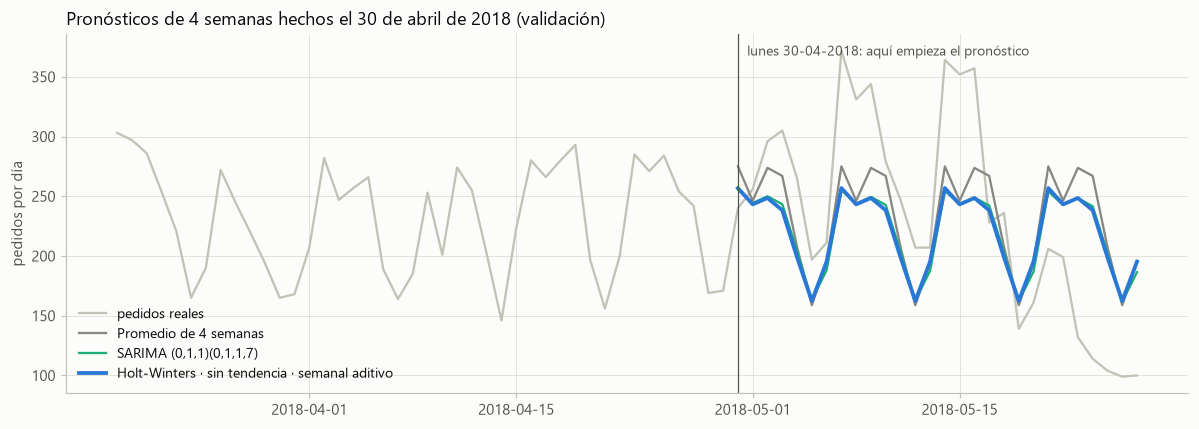

In [8]:
# El mejor de cada familia y el mejor en general
mejor_hw = tabla_val.loc[list(configs_hw), "MAE"].idxmin()
mejor_sarima = tabla_val.loc[list(configs_sarima), "MAE"].idxmin()
mejor_baseline = tabla_val.loc[["La semana pasada", "Promedio de 4 semanas"], "MAE"].idxmin()
mejor_nombre = tabla_val.loc[[mejor_hw, mejor_sarima], "MAE"].idxmin()
print(f"Mejor Holt-Winters: {mejor_hw}\nMejor SARIMA: {mejor_sarima}\nModelo elegido: {mejor_nombre}")

# Gráfico: pronósticos de 4 semanas hechos el lunes 30 de abril de 2018, contra lo que pasó
origen = INICIO_VAL
fig, ax = plt.subplots(figsize=(11, 4))
historia_reciente = serie[origen - pd.Timedelta(days=42):origen + pd.Timedelta(days=27)]
ax.plot(historia_reciente.index, historia_reciente, color=EJE, linewidth=1.5, label="pedidos reales")
for nombre, color in [(mejor_baseline, TENUE), (mejor_sarima, AQUA), (mejor_hw, AZUL)]:
    r = resultados_val[nombre]
    r = r[r["origen"] == origen]
    ax.plot(r["fecha"], r["pronostico"], color=color, linewidth=2.5 if nombre == mejor_nombre else 1.5, label=nombre)
ax.axvline(origen, color=TINTA_2, linewidth=0.8)
ax.annotate("lunes 30-04-2018: aquí empieza el pronóstico", xy=(origen, ax.get_ylim()[1]), xytext=(6, -14),
            textcoords="offset points", fontsize=9, color=TINTA_2)
ax.set(title="Pronósticos de 4 semanas hechos el 30 de abril de 2018 (validación)", ylabel="pedidos por día")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**¿Qué vemos?** Los tres pronósticos copian bien el patrón semanal (más pedidos los lunes y menos los sábados), pero ninguno anticipa lo que pasó: a comienzos de mayo hubo muchos más pedidos de lo normal y a fines de mayo cayeron a la mitad. Holt-Winters y SARIMA dan pronósticos casi iguales.

**¿Qué decidimos?** Elegir **Holt-Winters sin tendencia y con patrón semanal aditivo**: es el de menor error y el más fácil de explicar, porque solo combina el nivel actual de pedidos con el patrón de la semana.

## 6. La prueba de verdad

Ahora evaluamos el modelo elegido **una sola vez** en el período de prueba, del 25 de junio al 19 de agosto de 2018, con el mismo método de origen móvil. En cada lunes el modelo se vuelve a entrenar con todos los días anteriores, incluida la validación. Para comparar, hacemos lo mismo con los dos baselines.

Para el **entrenamiento** usamos el ajuste del modelo dentro de los mismos datos con que aprendió: cada día se predice con los días anteriores.

In [9]:
# Métricas en entrenamiento, validación y prueba del modelo elegido, y de los baselines en prueba
ajuste_ent = ajustar(mejor_nombre, entrenamiento)
ajustados = ajuste_ent.fittedvalues.iloc[14:]  # los primeros 14 días no tienen suficiente historia
resultados_pru = {nombre: evaluar_pronostico(f, INICIO_PRU, FIN)
                  for nombre, f in {mejor_nombre: modelo_pronostico(mejor_nombre), "La semana pasada": semana_pasada,
                                    "Promedio de 4 semanas": promedio_4_semanas}.items()}
filas = [{"modelo": mejor_nombre, "conjunto": "entrenamiento", **metricas(entrenamiento.iloc[14:], ajustados)},
         {"modelo": mejor_nombre, "conjunto": "validación", **metricas(resultados_val[mejor_nombre]["real"],
                                                                      resultados_val[mejor_nombre]["pronostico"])}]
filas += [{"modelo": nombre, "conjunto": "prueba", **metricas(r["real"], r["pronostico"])}
          for nombre, r in resultados_pru.items()]
resultado_final = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
resultado_final

MAE  RMSE  \
modelo                                         conjunto                    
Holt-Winters · sin tendencia · semanal aditivo entrenamiento 17.83 23.81   
                                               validación    54.84 69.46   
                                               prueba        55.85 67.72   
La semana pasada                               prueba        61.16 78.40   
Promedio de 4 semanas                          prueba        61.54 73.79   

                                                              MAPE (%)    R²  
modelo                                         conjunto                       
Holt-Winters · sin tendencia · semanal aditivo entrenamiento     13.78  0.88  
                                               validación        33.00 -0.13  
                                               prueba            24.61 -0.04  
La semana pasada                               prueba            26.60 -0.39  
Promedio de 4 semanas                          prueba            26.17 -0.23

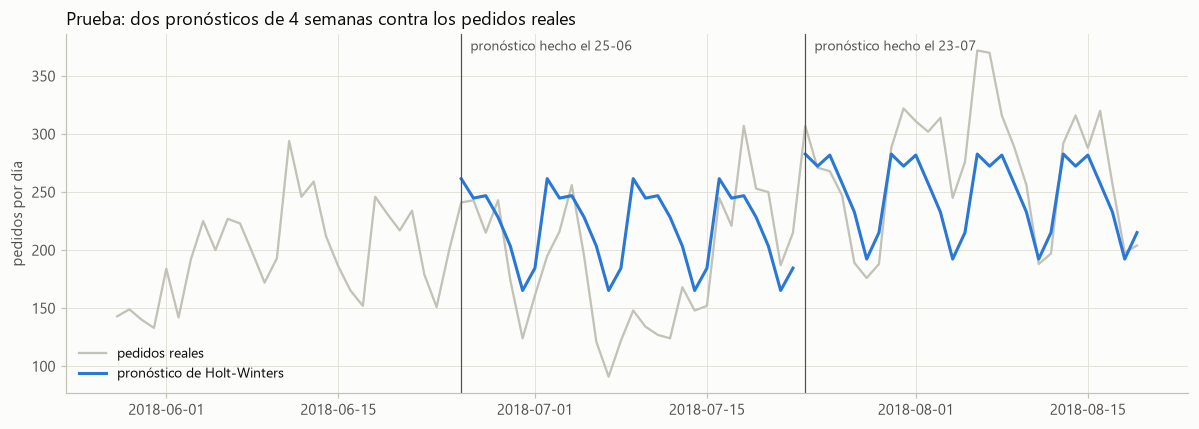

In [10]:
# Gráfico de la prueba: dos pronósticos de 4 semanas (hechos el 25 de junio y el 23 de julio) contra lo real
r = resultados_pru[mejor_nombre]
fig, ax = plt.subplots(figsize=(11, 4))
tramo = serie[INICIO_PRU - pd.Timedelta(days=28):]
ax.plot(tramo.index, tramo, color=EJE, linewidth=1.5, label="pedidos reales")
for i, origen in enumerate([INICIO_PRU, INICIO_PRU + pd.Timedelta(days=28)]):
    parte = r[r["origen"] == origen]
    ax.plot(parte["fecha"], parte["pronostico"], color=AZUL, linewidth=2,
            label=f"pronóstico de {mejor_nombre.split(' ·')[0]}" if i == 0 else None)
    ax.axvline(origen, color=TINTA_2, linewidth=0.8)
    ax.annotate(f"pronóstico hecho el {origen:%d-%m}", xy=(origen, tramo.max()), xytext=(6, 0),
                textcoords="offset points", fontsize=9, color=TINTA_2)
ax.set(title="Prueba: dos pronósticos de 4 semanas contra los pedidos reales", ylabel="pedidos por día")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- En la prueba, Holt-Winters se equivoca en promedio **55,9 pedidos por día (25%)**, menos que la semana pasada (61,2) y que el promedio de 4 semanas (61,5).
- En el gráfico se ve que el pronóstico sigue bien el patrón semanal, pero no los cambios de nivel: a comienzos de julio los pedidos bajaron mucho y el modelo predijo de más; a comienzos de agosto subieron y predijo de menos.
- En entrenamiento el error es mucho menor (17,8 pedidos, R² de 0,88), pero no es comparable: ahí el modelo predice solo **el día siguiente** con datos que ya conoce, mientras que en validación y prueba predice **hasta 4 semanas** hacia adelante.

## 7. Un rango en vez de un solo número

Igual que en la regresión, la aplicación va a mostrar un **rango probable** para cada día. Lo calculamos con los errores del modelo en la prueba, pero en porcentaje, porque un error de 30 pedidos no significa lo mismo cuando la tienda vende 100 que cuando vende 300. Buscamos entre qué porcentajes quedó el 80% de los días (del percentil 10 al percentil 90).

In [11]:
# Errores en porcentaje: cuánto estuvo lo real por encima (+) o por debajo (−) del pronóstico
error_relativo = r["real"] / r["pronostico"] - 1
p10, p90 = np.percentile(error_relativo, [10, 90])
print(f"En el 80% de los días de prueba, los pedidos reales estuvieron entre {p10:+.0%} y {p90:+.0%} del pronóstico")

En el 80% de los días de prueba, los pedidos reales estuvieron entre -25% y +55% del pronóstico


**¿Qué vemos?** En el 80% de los días de prueba, los pedidos reales estuvieron entre un 25% por debajo y un 55% por encima del pronóstico. El rango es más grande hacia arriba porque los días con muchos más pedidos de lo esperado, como a comienzos de agosto, fueron más comunes que los días con muchos menos.

**¿Qué decidimos?** La aplicación muestra cada día con su rango: desde el pronóstico × 0,75 hasta el pronóstico × 1,55.

## 8. Modelo final para la aplicación

Volvemos a entrenar el modelo elegido con **todos los días** (del 5 de enero de 2017 al 19 de agosto de 2018) y lo guardamos. La aplicación le va a pedir el pronóstico de los días siguientes al último dato, es decir, **desde el 20 de agosto de 2018**, porque el dataset termina ahí.

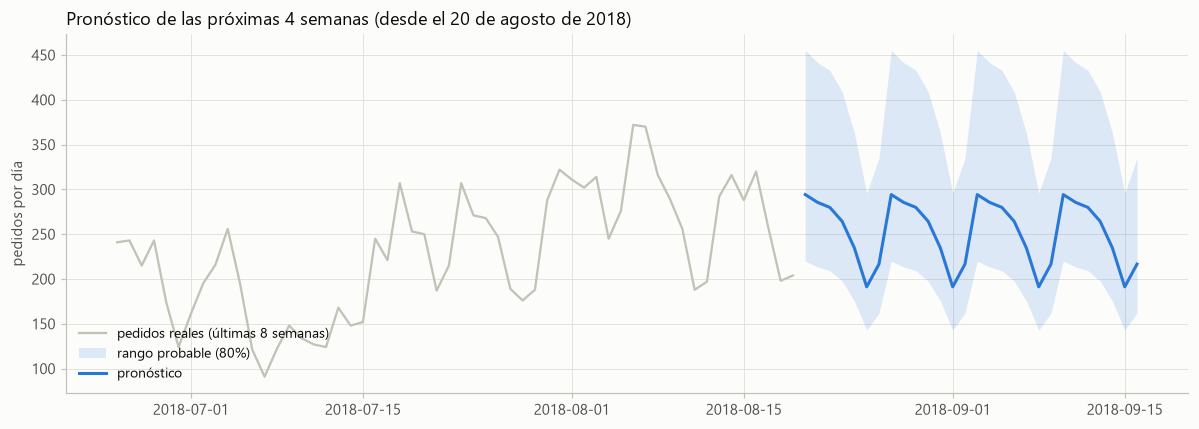

serie_pedidos.joblib: 0.03 MB
{
  "modelo": "Holt-Winters · sin tendencia · semanal aditivo",
  "objetivo": "pedidos por día",
  "ultima_fecha": "2018-08-19",
  "horizonte_maximo_dias": 28,
  "rango_error_relativo": {
    "p10": -0.2523,
    "p90": 0.5466,
    "explicacion": "rango probable = pronóstico × (1 + p10) hasta pronóstico × (1 + p90)"
  },
  "limpieza": "Black Friday (24 al 29 de noviembre de 2017) reemplazado por el promedio del mismo día de las 2 semanas anteriores",
  "entrenado_con": "todos los días de 2017-01-05 a 2018-08-19",
  "metricas_validacion": {
    "MAE": 54.8419,
    "RMSE": 69.4612,
    "MAPE (%)": 32.9991,
    "R²": -0.1331
  },
  "metricas_prueba": {
    "MAE": 55.8533,
    "RMSE": 67.7217,
    "MAPE (%)": 24.6079,
    "R²": -0.0379
  },
  "version_statsmodels": "0.15.0",
  "fecha": "2026-11-15"
}


In [12]:
# Entrenamos con todos los días, pronosticamos 4 semanas y guardamos el modelo y su descripción
modelo_app = ajustar(mejor_nombre, serie)
futuro = modelo_app.forecast(28)
pronostico = pd.DataFrame({"pedidos": futuro, "mínimo": futuro * (1 + p10), "máximo": futuro * (1 + p90)})

fig, ax = plt.subplots(figsize=(11, 4))
reciente = serie[FIN - pd.Timedelta(days=55):]
ax.plot(reciente.index, reciente, color=EJE, linewidth=1.5, label="pedidos reales (últimas 8 semanas)")
ax.fill_between(pronostico.index, pronostico["mínimo"], pronostico["máximo"], color=AZUL, alpha=0.15, linewidth=0,
                label="rango probable (80%)")
ax.plot(pronostico.index, pronostico["pedidos"], color=AZUL, linewidth=2, label="pronóstico")
ax.set(title="Pronóstico de las próximas 4 semanas (desde el 20 de agosto de 2018)", ylabel="pedidos por día")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

ruta_modelo = MODELOS / "serie_pedidos.joblib"
joblib.dump(modelo_app, ruta_modelo, compress=3)
metadatos = {
    "modelo": mejor_nombre,
    "objetivo": "pedidos por día",
    "ultima_fecha": FIN.date().isoformat(),
    "horizonte_maximo_dias": 28,
    "rango_error_relativo": {"p10": round(float(p10), 4), "p90": round(float(p90), 4),
                             "explicacion": "rango probable = pronóstico × (1 + p10) hasta pronóstico × (1 + p90)"},
    "limpieza": "Black Friday (24 al 29 de noviembre de 2017) reemplazado por el promedio del mismo día de las 2 semanas anteriores",
    "entrenado_con": f"todos los días de {serie.index.min().date()} a {FIN.date()}",
    "metricas_validacion": {k: round(float(v), 4) for k, v in resultado_final.loc[(mejor_nombre, "validación")].items()},
    "metricas_prueba": {k: round(float(v), 4) for k, v in resultado_final.loc[(mejor_nombre, "prueba")].items()},
    "version_statsmodels": statsmodels.__version__,
    "fecha": date.today().isoformat(),
}
(MODELOS / "serie_pedidos.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"{ruta_modelo.name}: {ruta_modelo.stat().st_size / 1e6:.2f} MB")
print(json.dumps(metadatos, indent=2, ensure_ascii=False))

In [13]:
# Probamos el modelo guardado, como lo hará la aplicación: pronóstico de los próximos 7 días
modelo_cargado = joblib.load(ruta_modelo)
siete = modelo_cargado.forecast(7)
assert np.allclose(siete.to_numpy(), futuro.iloc[:7].to_numpy())
nombres_dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
display(pd.DataFrame({"día": [f"{nombres_dias[d.weekday()]} {d:%d-%m-%Y}" for d in siete.index],
                      "pedidos esperados": siete.round().astype(int).to_numpy()}))

,día,pedidos esperados
0,lun 20-08-2018,294
1,mar 21-08-2018,286
2,mié 22-08-2018,280
3,jue 23-08-2018,264
4,vie 24-08-2018,235
5,sáb 25-08-2018,191
6,dom 26-08-2018,217


## 9. Conclusiones

**Resumen del modelo**

| | |
|---|---|
| Modelo elegido | Holt-Winters sin tendencia, con patrón semanal aditivo (ciclo de 7 días) |
| Cómo lo elegimos | 6 configuraciones de Holt-Winters y 3 de SARIMA, evaluadas con origen móvil en validación (8 lunes, hasta 28 días cada vez); la de menor MAE |
| Validación | MAE de 54,8 pedidos por día · MAPE 33% (mejor baseline: 57,4) |
| Prueba | MAE de 55,9 pedidos por día · MAPE 25% (mejor baseline: 61,2) |
| Rango probable | de −25% a +55% del pronóstico (80% de los días de prueba) |

**¿Qué significa?** El modelo captura bien el patrón semanal de la tienda y se equivoca menos que las predicciones simples. Pero los cambios bruscos de nivel, como la caída durante la huelga de mayo o la subida de agosto, no se pueden anticipar solo con los pedidos pasados.

**Limitaciones**

- No sabe de eventos especiales como el Black Friday, los feriados o las huelgas. Limpiamos el Black Friday del entrenamiento, pero el modelo no pronosticaría uno futuro.
- El error crece cuando la tienda cambia de nivel rápido.
- El pronóstico empieza el 20 de agosto de 2018, porque ahí terminan los datos.

**¿Cómo se podría mejorar?**

- Agregar los días especiales (Black Friday, Navidad, feriados) como información para el modelo.
- Volver a entrenarlo cada semana con los datos más nuevos.
- Probar modelos que usen información externa, como las campañas de publicidad de la tienda.

**Archivos para la aplicación:** `models/serie_pedidos.joblib` y `models/serie_pedidos.json`.